# 5.2 - Model: Logistic Regression (lemmatized variant)

**Training and evaluation of the Logistic Regression classifier on the lemmatized variant of the TF-IDF data.**

## Theoretical basis

Logistic Regression is a linear model that calculates a weighted sum of features `z = w * x + b` (token * learned weight + bias that the model also learns), and then passes it through the sigmoid function `σ(z) = 1 / (1 + e^-z)` to obtain a probability between 0 and 1 (P >= 0.5 → positive | P <  0.5 → negative).

The model is trained by minimizing cross-entropy (log-loss) between the predicted probabilities and the actual labels:

  - At the beginning, the model does not know the right values of `w`; during training, it tries to find weights that produce the best possible predictions

  - For this, a loss function is used, i.e. log-loss / cross-entropy loss
  
    - If the actual class is positive and the model says P(positive) = 0.99 → excellent prediction → small loss
    - If the actual class is positive and the model says P(positive) = 0.01 → very incorrect prediction → large loss

Unlike Naive Bayes (which assumes feature independence and models the distribution of features by class), Logistic Regression directly learns the decision boundary - it does not have to model the entire joint distribution, only the combination of weights that best separates the classes.

## Why regularization is particularly important here

Our vocabulary has `66.834` terms, while the train set has `39.665` reviews - therefore there are more features than examples (the so-called `p > n` regime).

Ideally, the model should learn patterns that also appear in new reviews, but a highly flexible model may instead learn that a particular review had some specific words, and remember exactly that.

In other words, without regularization, the model could almost trivially "memorize" the train set in such a large space (overfitting), without actually generalizing to new data.

Regularization essentially tells the model: "Don't just try to fit the training data as well as possible. You also pay a penalty if you use excessively large/complex coefficients."

Therefore, choosing the regularization strength is fundamentally important here; we want neither:
  - too much regularization → the model becomes too simple
  - too little regularization → the model may overfit

## Processing flow:

1. We load the previously prepared lemmatized TF-IDF data using the `load_variant()` function

2. We create a `LogisticRegression` classifier and define the `C` and `l1_ratio` hyperparameter values that `GridSearchCV` will test

3. We call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - tests all combinations of hyperparameters from the param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the hyperparameter combination that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used on the TEST set for the first time
        - accuracy, precision, recall, and F1 are calculated, and a confusion matrix is created
    4. Saving the results

4. We analyze the terms with the largest positive and negative coefficients in order to determine which terms have the greatest influence on sentiment classification


In [1]:
import sys
sys.path.append("..")

import numpy as np
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.linear_model import LogisticRegression

## Loading the data

We load the lemmatized variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("lemmatized")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 66834)
Test:  (9917, 66834)


## Model and hyperparameters

Hyperparameters: `C` and `l1_ratio`

- `C` - inversely proportional to the strength of regularization (smaller `C` = stronger regularization, larger `C` = weaker regularization)

- `l1_ratio` - controls the balance between L2 and L1 regularization:
  - `l1_ratio=0.0` - pure L2 (Ridge) - uniformly reduces all coefficients toward zero, retains all features
  - `l1_ratio=1.0` - pure L1 (Lasso) - forces many coefficients exactly to zero, effectively performing automatic feature selection
  - Solver: we use `liblinear` - it supports both L1 and L2 regularization, which is what we need to compare the two extreme variants.
  - Values between 0 and 1 ("true" elastic net) require `solver="saga"` - `liblinear` does not support them, so we test only the two extreme values

`max_iter`:
  - The maximum number of iterations the solver is allowed to perform while trying to find the optimal solution.
  - We increase it to 1000 (100 by default) to avoid a non-convergence warning in such a large feature space.


In [3]:
model = LogisticRegression(solver="liblinear", max_iter=1000, random_state=1)

param_grid = {
    "C": [0.01, 0.1, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0],
    "l1_ratio": [0.0, 1.0],
}

## Training and evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified combinations of `C` and `l1_ratio` values using 5-fold GridSearchCV on the train set, selects the combination with the best F1 score, then trains the best model on the entire train set and evaluates it on the test set.

The results are saved as the model, metrics, and confusion matrix.


========== logistic_regression (lem) ==========
Best parameters: {'C': 7.0, 'l1_ratio': 0.0}
GridSearchCV time: 71.2s

Accuracy  : 0.9084
Precision : 0.9012
Recall    : 0.9182
F1        : 0.9096


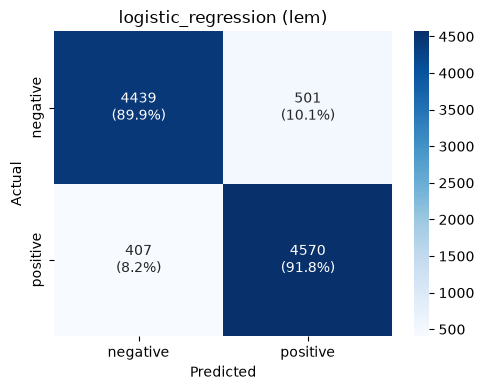


Saved:
  ..\models\logistic_regression_lem.joblib
  ..\results\metrics\logistic_regression_lem.json
  ..\results\figures\logistic_regression_lem_confusion_matrix.png


In [4]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="logistic_regression",
    variant="lem",
)

## Most influential terms (coefficient interpretation)

Unlike Naive Bayes, the coefficients of Logistic Regression can be directly interpreted as "how much the presence of this term pushes the prediction toward positive (positive coefficient) or negative (negative coefficient) sentiment".

This is a direct check of whether the process of preserving negations (`2_preprocessing.ipynb`) and bigrams (`3_vectorization.ipynb`) is actually being "used" by the model - we expect terms such as "not_good" - bigrams and negation words to be among the most influential for the negative class.

We load the saved model and vectorizer that we saved in the previous step and test them.


In [5]:
best_model = joblib.load("../models/logistic_regression_lem.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_lem.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = best_model.coef_[0]

top_positive_idx = np.argsort(coefficients)[-20:][::-1]
top_negative_idx = np.argsort(coefficients)[:20]

print("Top 20 terms most strongly associated with POSITIVE sentiment:")
for idx in top_positive_idx:
    print(f"  {feature_names[idx]:30s}  {coefficients[idx]:+.3f}")

print("\nTop 20 terms most strongly associated with NEGATIVE sentiment:")
for idx in top_negative_idx:
    print(f"  {feature_names[idx]:30s}  {coefficients[idx]:+.3f}")

n_zero_coefs = np.sum(coefficients == 0)
print(f"\nNumber of coefficients set exactly to 0: {n_zero_coefs} out of {len(coefficients)} ({n_zero_coefs / len(coefficients):.1%}) - relevant only if l1_ratio=1.0 (L1)")

Top 20 terms most strongly associated with POSITIVE sentiment:
  excellent                       +11.628
  great                           +11.376
  perfect                         +9.076
  wonderful                       +8.104
  hilarious                       +7.950
  fun                             +7.750
  best                            +7.641
  favorite                        +7.603
  today                           +7.380
  brilliant                       +7.282
  superb                          +6.948
  one best                        +6.806
  enjoy                           +6.737
  well worth                      +6.591
  must see                        +6.500
  enjoyable                       +6.419
  love                            +6.322
  perfectly                       +6.275
  refresh                         +6.230
  highly recommend                +6.150

Top 20 terms most strongly associated with NEGATIVE sentiment:
  bad                             -15.231
  awful  

## Conclusions

- Best `C`: 7.0, `l1_ratio`: 0.0

- Results:
  - Accuracy  : 0.9084
  - Precision : 0.9012
  - Recall    : 0.9182
  - F1        : 0.9096

- Most influential terms:
  -  largely correspond to expectations (in addition to the expected words, negation unigrams and bigrams also appear among the most influential)
  - For positive sentiment, terms such as: great, excellent, perfect, amazing and wonderful stand out in particular
  - For positive sentiment, terms such as: worst, awful, bad, boring and waste stand out in particular

- The statistical analysis from `3_vectorization.ipynb` (`min_df` experiment), where we showed that there are thousands of terms with moderate (not extreme) class deviations.
This aligns well with what we obtained here: L2 captures terms with weak signals better, while L1 would partially discard them through aggressive elimination.
